# BANKING77 with gpt-oss: how much should a model think?

Qwen3.5 can only switch thinking on or off (notebook 02 limited it with budget forcing). OpenAI's open-weight
**gpt-oss** was trained with three **reasoning efforts**: `low`, `medium` and `high`. The effort is set in the
system prompt; in Ollama it is `think="low" | "medium" | "high"`. gpt-oss always reasons; it cannot switch
thinking off.

`gpt-oss:20b` has 21B parameters, of which 3.6B are active per token (mixture of experts), similar to
`qwen3.6:35b-a3b` (3B active). At 14 GB it does not fit into the 8 GB GPU; about half of it runs on the CPU,
so its latencies are not comparable to the small Qwen models that run fully on the GPU.

Setup: same prompt and constrained output as before, same balanced subset (5 queries per intent, 385 queries),
OpenAI's recommended sampling (temperature 1.0, top-p 1.0), at most 8,192 generated tokens.
Run with `scripts/run_banking77.py --models gpt-oss:20b --effort {low,medium,high} --per-class 5 --logprobs`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from slm import RESULTS_DIR
from slm.data import load_banking77
from slm.evaluation import score, stratified_subset

RUN_DIR = RESULTS_DIR / "banking77"
EFFORTS = ["low", "medium", "high"]

dataset = load_banking77()
subset = stratified_subset(dataset.test, per_class=5)


def load(run, model):
    path = RUN_DIR / run / f"{model.replace(':', '_')}.jsonl"
    records = pd.DataFrame([json.loads(line) for line in path.read_text().splitlines()]).set_index("idx")
    results = subset.join(records, how="inner")
    results["correct"] = results["prediction"] == results["label"]
    return results


gpt_oss = {effort: load(f"structured_effort-{effort}", "gpt-oss:20b") for effort in EFFORTS
           if (RUN_DIR / f"structured_effort-{effort}" / "gpt-oss_20b.jsonl").exists()
           and (RUN_DIR / f"structured_effort-{effort}" / "gpt-oss_20b.jsonl").stat().st_size}
pd.DataFrame({effort: score(r) for effort, r in gpt_oss.items()}).T[
    ["n", "accuracy", "invalid_rate", "mean_completion_tokens", "mean_latency_s", "p95_latency_s", "truncated_rate"]
].round(3)

/home/phth01/PycharmProjects/small-language-models/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,n,accuracy,invalid_rate,mean_completion_tokens,mean_latency_s,p95_latency_s,truncated_rate
low,385.0,0.784,0.000,46.374,20.377,32.711,0.000
medium,385.0,0.795,0.000,206.813,67.553,144.115,0.000
high,385.0,0.813,0.013,649.629,205.361,665.198,0.013


## 1. Accuracy and cost per effort

All on the same 385 queries. Latency is the mean time per query with 4 concurrent requests (log scale).
For comparison, the best Qwen model, `qwen3.6:35b-a3b` without thinking, reaches 0.751 on these queries.

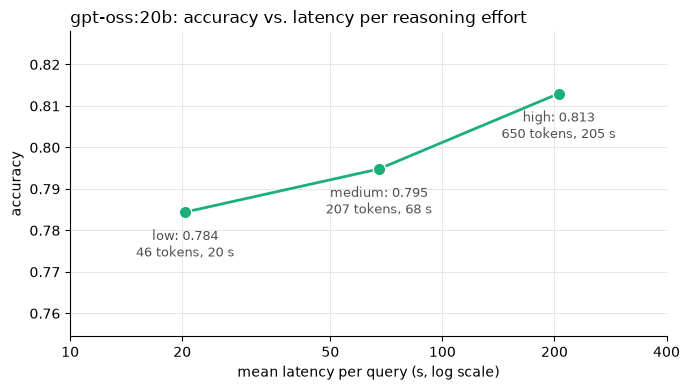

In [2]:
points = pd.DataFrame([{"effort": effort, "accuracy": r["correct"].mean(), "latency_s": r["latency_s"].mean(),
                        "tokens": r["completion_tokens"].mean()} for effort, r in gpt_oss.items()])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(points["latency_s"], points["accuracy"], color="#1baf7a", linewidth=2, marker="o", markersize=9,
        markeredgecolor="white")
for _, p in points.iterrows():
    ax.annotate(f"{p['effort']}: {p['accuracy']:.3f}\n{p['tokens']:.0f} tokens, {p['latency_s']:.0f} s",
                (p["latency_s"], p["accuracy"]), textcoords="offset points", xytext=(0, -32), ha="center",
                fontsize=9, color="#52514e")
ax.set_xscale("log")
ax.set_xlim(points["latency_s"].min() / 1.8, points["latency_s"].max() * 1.8)
ax.set_xticks([10, 20, 50, 100, 200, 400], ["10", "20", "50", "100", "200", "400"])
ax.minorticks_off()
ax.set_ylim(points["accuracy"].min() - 0.03, points["accuracy"].max() + 0.015)
ax.set_xlabel("mean latency per query (s, log scale)")
ax.set_ylabel("accuracy")
ax.set_title("gpt-oss:20b: accuracy vs. latency per reasoning effort", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="#e4e3df", linewidth=0.6)
ax.set_axisbelow(True)
plt.tight_layout()

## 2. How much does it think?

Number of generated tokens per query (reasoning plus the short JSON answer), per effort.

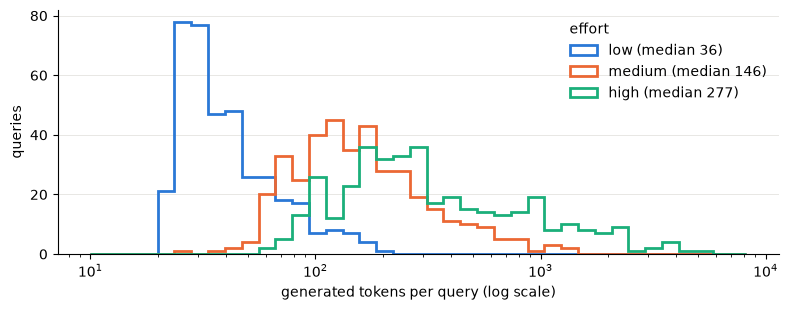

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.logspace(1, np.log10(8192), 40)
for effort, color in zip(gpt_oss, ["#2a78d6", "#eb6834", "#1baf7a"]):
    tokens = gpt_oss[effort]["completion_tokens"]
    ax.hist(tokens, bins=bins, histtype="step", linewidth=2, color=color,
            label=f"{effort} (median {tokens.median():.0f})")
ax.set_xscale("log")
ax.set_xlabel("generated tokens per query (log scale)")
ax.set_ylabel("queries")
ax.legend(frameon=False, title="effort", alignment="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e4e3df", linewidth=0.6)
ax.set_axisbelow(True)
plt.tight_layout()

In [4]:
# The same query at each effort
idx = subset.index[0]
print("QUERY:", subset.at[idx, "text"], "| GOLD:", subset.at[idx, "label"], "\n")
for effort, r in gpt_oss.items():
    print(f"--- {effort}: {r.at[idx, 'prediction']} ({r.at[idx, 'completion_tokens']} tokens)")
    print(r.at[idx, "thinking"][:1500], "\n")

QUERY: When will I get my card? | GOLD: card_arrival 

--- low: card_arrival (32 tokens)
This is asking about card arrival. So intent: card_arrival. 

--- medium: card_delivery_estimate (184 tokens)
We need to classify the message: "When will I get my card?" The intents related to card arrival or estimated delivery: there is "card_arrival" and "card_delivery_estimate". There is also "card_delivery_estimate" specifically for estimated shipping time. The question: "When will I get my card?" Usually it's about delivery estimate. The intent "card_delivery_estimate" matches.

But let's confirm: "When will I get my card?" -> That is basically asking about delivery time. Among the options: "card_arrival" is generic arrival maybe after it's shipped. "card_delivery_estimate" likely the question: When will I get it. So likely "card_delivery_estimate".

Thus the label: card_delivery_estimate.

Return JSON: {"label": "card_delivery_estimate"} 

--- high: card_arrival (2215 tokens)
We need to deter

## 3. Which queries change with more effort?

Comparing the answers per query between the lowest and the highest effort.

In [5]:
if "low" in gpt_oss and "high" in gpt_oss:
    low, high = gpt_oss["low"]["correct"], gpt_oss["high"]["correct"].reindex(gpt_oss["low"].index)
    print(pd.crosstab(low.rename("low correct"), high.rename("high correct"), margins=True))

high correct  False  True  All
low correct                   
False            65    18   83
True              7   295  302
All              72   313  385


## 4. Confidence after reasoning

For the Qwen models without thinking, the probability of the generated label was a useful confidence signal
(notebook 04). After reasoning, the answer is already decided, so its probability is almost always close to 1.
An alternative signal is **how long the model thinks**: does a long reasoning trace indicate a hard query?

In [6]:
rows = []
for effort, r in gpt_oss.items():
    rows.append({
        "effort": effort,
        "accuracy": r["correct"].mean(),
        "label_prob >= 0.99": (r["label_prob"] >= 0.99).mean(),
        "AUROC label_prob": roc_auc_score(r["correct"], r["label_prob"].fillna(0)),
        "AUROC short reasoning": roc_auc_score(r["correct"], -r["completion_tokens"]),
        "tokens if correct": r.loc[r["correct"], "completion_tokens"].median(),
        "tokens if wrong": r.loc[~r["correct"], "completion_tokens"].median(),
    })
pd.DataFrame(rows).round(3)

,effort,accuracy,label_prob >= 0.99,AUROC label_prob,AUROC short reasoning,tokens if correct,tokens if wrong
0,low,0.784,0.995,0.646,0.767,33.0,60.0
1,medium,0.795,0.997,0.432,0.819,125.5,304.0
2,high,0.813,0.987,0.388,0.778,238.0,866.0


## Takeaways

* **gpt-oss:20b is the best model in this talk, already at low effort**: 0.784 with a median of 36 reasoning
  tokens, vs. 0.751 for `qwen3.6:35b-a3b` on the same queries. Its reasoning is short by default, whereas Qwen's
  thinking mode only paid off with budget forcing (notebook 02).
* **More effort helps a little, at a steep price**: medium 0.795 (+1.1 points, 4.5x the tokens, 3x the latency),
  high 0.813 (+2.9 points, 14x the tokens, 10x the latency). Between low and high, 18 answers are fixed and 7 broken;
  1.3% of the high-effort traces hit the 8,192-token limit.
* **More thinking is not always better**: in the example above, medium effort talks itself out of the right answer.
  The ambiguity between near-duplicate intents (`card_arrival` vs. `card_delivery_estimate`) remains the main error
  source, for every model.
* **Confidence after reasoning**: the probability of the final answer is useless (>= 0.99 for nearly every query;
  the AUROC values around or below 0.5 are noise). Instead, **reasoning length** is a good signal (AUROC 0.77-0.82):
  wrong answers take 2-3.5x as many tokens as correct ones. A reasoning model that thinks long is unsure,
  which can be used for routing as in notebook 04.

**Caveats**: half of gpt-oss:20b runs on the CPU of this laptop, so its latencies are not comparable to the small
Qwen models on the GPU; on a 16 GB GPU it would be much faster. And BANKING77 is public since 2020; newer models may
have seen it during training.